First 5 Records:
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  
0 

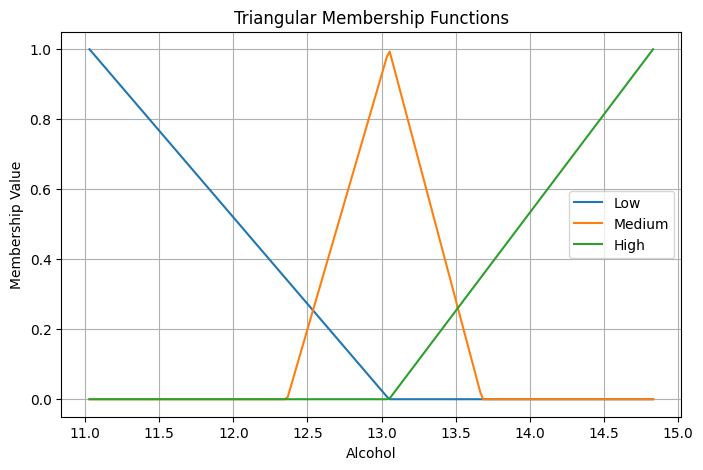


Membership Values:
   Alcohol  Low    Medium      High
0    14.23  0.0  0.000000  0.662921
1    13.20  0.0  0.760956  0.084270
2    13.16  0.0  0.824701  0.061798
3    14.37  0.0  0.000000  0.741573
4    13.24  0.0  0.697211  0.106742
5    14.20  0.0  0.000000  0.646067
6    14.39  0.0  0.000000  0.752809
7    14.06  0.0  0.000000  0.567416
8    14.83  0.0  0.000000  1.000000
9    13.86  0.0  0.000000  0.455056

Fuzzy Operations:
   Low      High  AND (Low, High)  OR (Low, High)  NOT Low
0  0.0  0.662921              0.0        0.662921      1.0
1  0.0  0.084270              0.0        0.084270      1.0
2  0.0  0.061798              0.0        0.061798      1.0
3  0.0  0.741573              0.0        0.741573      1.0
4  0.0  0.106742              0.0        0.106742      1.0
5  0.0  0.646067              0.0        0.646067      1.0
6  0.0  0.752809              0.0        0.752809      1.0
7  0.0  0.567416              0.0        0.567416      1.0
8  0.0  1.000000              0.0 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine

# Load Wine Dataset
wine = load_wine()

df = pd.DataFrame(wine.data,
columns=wine.feature_names)

print("First 5 Records:")
print(df.head())

# Select Feature
feature = "alcohol"
x = df[feature].values

# Universe of Discourse
xmin = x.min()
xmax = x.max()

universe = np.linspace(xmin, xmax, 200)

# Triangular Membership Function
def triangular(x, a, b, c):
    x = np.asarray(x)
    mu = np.zeros_like(x, dtype=float)

    # Rising edge
    if b != a:
        idx = (x >= a) & (x <= b)
        mu[idx] = (x[idx] - a) / (b - a)

    # Falling edge
    if c != b:
        idx = (x >= b) & (x <= c)
        mu[idx] = (c - x[idx]) / (c - b)

    mu[x == b] = 1
    return np.clip(mu, 0, 1)

# Membership Functions
low = triangular(
    universe,
    xmin,
    xmin,
    np.percentile(x, 50)
)

medium = triangular(
    universe,
    np.percentile(x, 25),
    np.percentile(x, 50),
    np.percentile(x, 75)
)

high = triangular(
    universe,
    np.percentile(x, 50),
    xmax,
    xmax
)

# Plot Membership Functions
plt.figure(figsize=(8,5))

plt.plot(universe, low, label="Low")
plt.plot(universe, medium, label="Medium")
plt.plot(universe, high, label="High")

plt.title("Triangular Membership Functions")
plt.xlabel(feature.capitalize())
plt.ylabel("Membership Value")
plt.legend()
plt.grid(True)

plt.show()




# Membership Calculation
low_membership = triangular(
    x,
    xmin,
    xmin,
    np.percentile(x, 50)
)

medium_membership = triangular(
    x,
    np.percentile(x, 25),
    np.percentile(x, 50),
    np.percentile(x, 75)
)

high_membership = triangular(
    x,
    np.percentile(x, 50),
    xmax,
    xmax
)

# Membership Table
membership = pd.DataFrame({
    "Alcohol": x,
    "Low": low_membership,
    "Medium": medium_membership,
    "High": high_membership
})

print("\nMembership Values:")
print(membership.head(10))

# Fuzzy Operations
membership["AND (Low, High)"] = np.minimum(
    membership["Low"],
    membership["High"]
)

membership["OR (Low, High)"] = np.maximum(
    membership["Low"],
    membership["High"]
)

membership["NOT Low"] = 1 - membership["Low"]

print("\nFuzzy Operations:")
print(
    membership[
        [
            "Low",
            "High",
            "AND (Low, High)",
            "OR (Low, High)",
            "NOT Low"
        ]
    ].head(10)
)

# Fuzzy Relation Matrix
low5 = membership["Low"].head(5).to_numpy()
high5 = membership["High"].head(5).to_numpy()

relation = np.zeros((5,5))

for i in range(5):
    for j in range(5):
        relation[i][j] = min(low5[i], high5[j])

relation_df = pd.DataFrame(
    relation,
    index=[f"L{i+1}" for i in range(5)],
    columns=[f"H{i+1}" for i in range(5)]
)

print("\nFuzzy Relation Matrix:")
print(relation_df)